In [31]:
from pathlib import Path
import rasterio
import numpy as np

CLOUDY_DIR = Path(r"D:\data2\cloudy")
CLEAR_DIR = Path(r"D:\data2\clear")

PAIR_ID = "Pair1_Bengaluru"

cloudy_folder = CLOUDY_DIR / PAIR_ID
clear_folder = CLEAR_DIR / PAIR_ID

BANDS = ["BAND2.tif", "BAND3.tif", "BAND4.tif"]

for band in BANDS:

    print(f"\n========== {band} ==========")

    for label, folder in [
        ("CLOUDY", cloudy_folder),
        ("CLEAR", clear_folder)
    ]:

        path = folder / band

        with rasterio.open(path) as src:
            print(f"\n{label}")
            print("Shape:", src.height, "x", src.width)
            print("CRS:", src.crs)
            print("Resolution:", src.res)
            print("Transform:", src.transform)
            print("Data type:", src.dtypes)
            print("Nodata:", src.nodata)
            print("Bounds:", src.bounds)


========== BAND2.tif ==========

CLOUDY
Shape: 16620 x 17731
CRS: PROJCS["WGS 84 / UTM zone 43N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.25722293287,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",75],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32643"]]
Resolution: (5.0, 5.0)
Transform: | 5.00, 0.00, 725973.94|
| 0.00,-5.00, 1534262.50|
| 0.00, 0.00, 1.00|
Data type: ('uint16',)
Nodata: None
Bounds: BoundingBox(left=725973.943083703, bottom=1451162.5, right=814628.943083703, top=1534262.5)

CLEAR
Shape: 16610 x 17747
CRS: PROJCS["WGS 84 / UTM zone 43N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",63

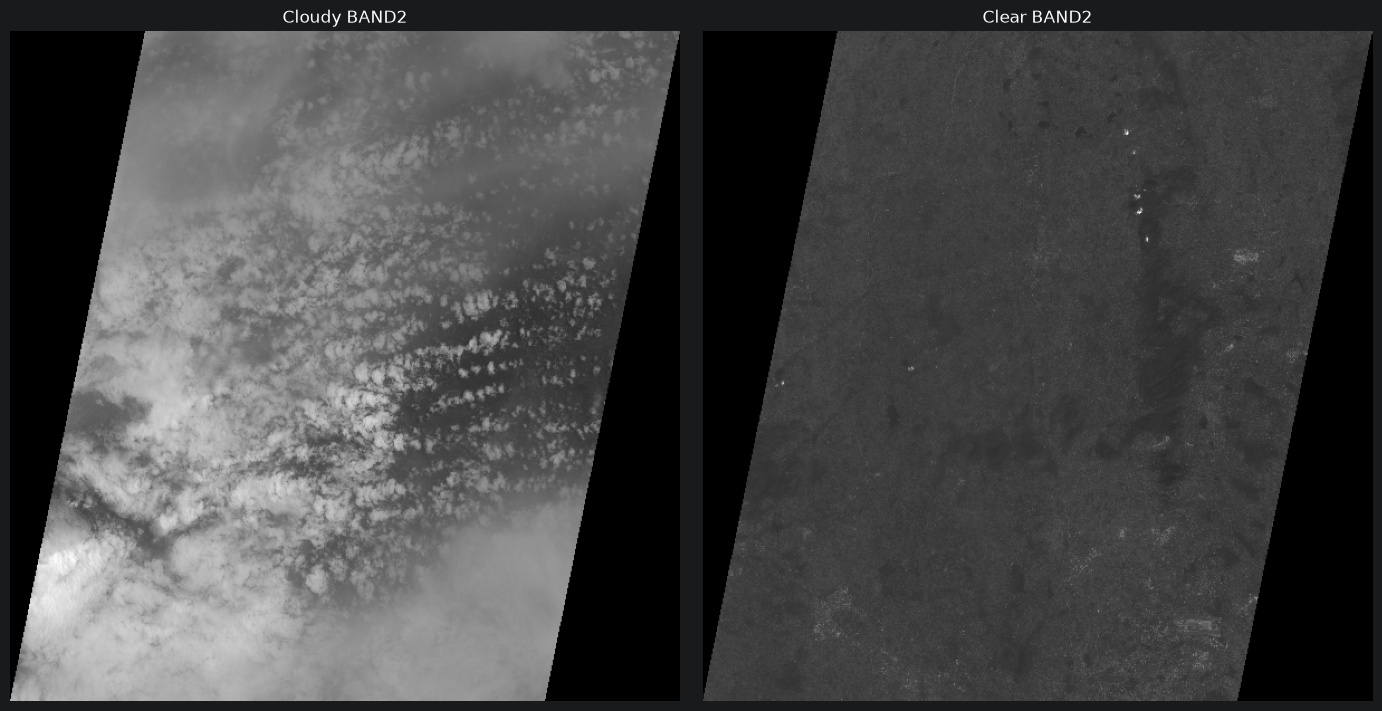

In [11]:
import matplotlib.pyplot as plt
from rasterio.enums import Resampling

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, folder, label in [
    (axes[0], cloudy_folder, "Cloudy BAND2"),
    (axes[1], clear_folder, "Clear BAND2")
]:
    with rasterio.open(folder / "BAND2.tif") as src:
        overview = src.read(
            1,
            out_shape=(600, 600),
            resampling=Resampling.nearest
        )

    ax.imshow(overview, cmap="gray")
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
for label, folder in [
    ("CLOUDY", cloudy_folder),
    ("CLEAR", clear_folder)
]:
    with rasterio.open(folder / "BAND2.tif") as src:
        band = src.read(1)

        zero_count = np.count_nonzero(band == 0)
        total_count = band.size

        print(f"\n{label}")
        print("Zero pixels:", zero_count)
        print("Total pixels:", total_count)
        print("Zero percentage:", round(100 * zero_count / total_count, 2))
        print("Minimum:", band.min())
        print("Maximum:", band.max())


CLOUDY
Zero pixels: 59367321
Total pixels: 294689220
Zero percentage: 20.15
Minimum: 0
Maximum: 907

CLEAR
Zero pixels: 59432472
Total pixels: 294777670
Zero percentage: 20.16
Minimum: 0
Maximum: 537


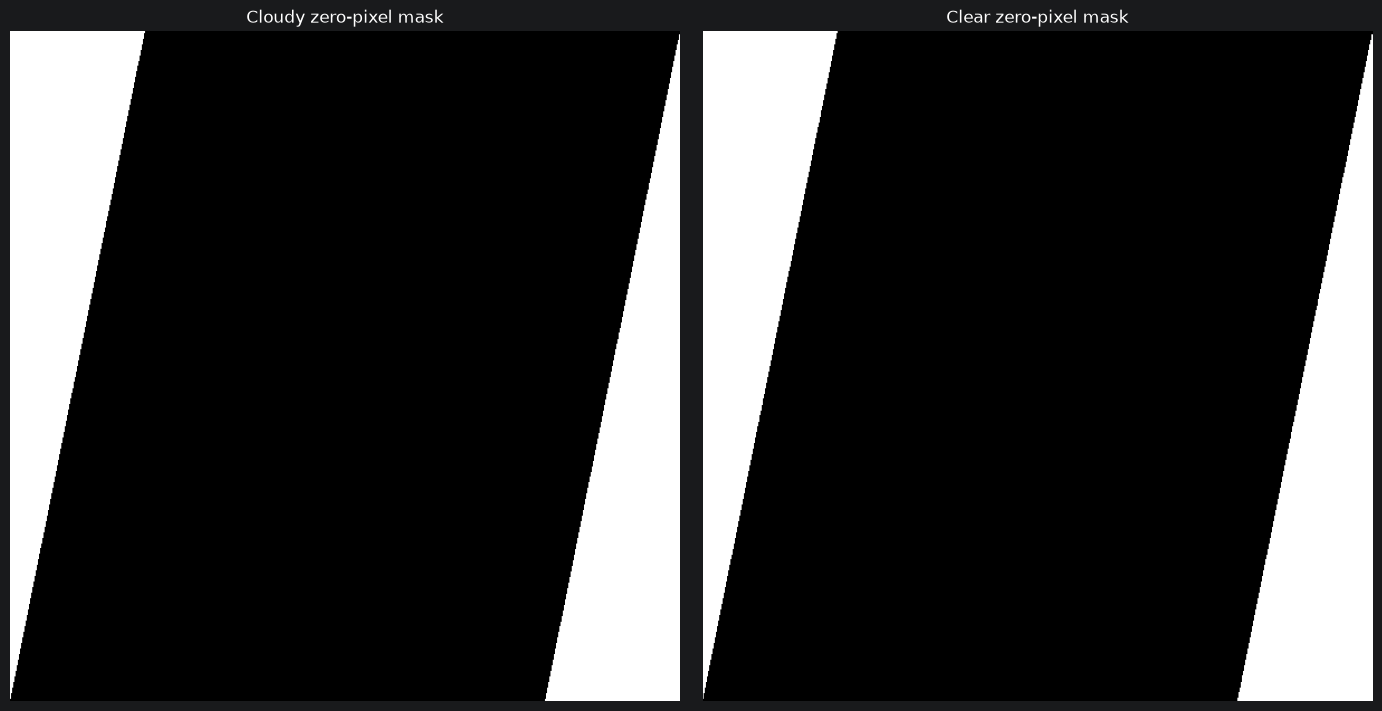

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, folder, label in [
    (axes[0], cloudy_folder, "Cloudy zero-pixel mask"),
    (axes[1], clear_folder, "Clear zero-pixel mask")
]:
    with rasterio.open(folder / "BAND2.tif") as src:
        mask = src.read(
            1,
            out_shape=(600, 600),
            resampling=Resampling.nearest
        ) == 0

    ax.imshow(mask, cmap="gray")
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import math
from rasterio.windows import Window

with rasterio.open(cloudy_folder / "BAND2.tif") as cloudy_src, \
     rasterio.open(clear_folder / "BAND2.tif") as clear_src:

    # Pixel offset of clear image relative to cloudy image
    col_offset = (
        clear_src.transform.c - cloudy_src.transform.c
    ) / cloudy_src.transform.a

    row_offset = (
        clear_src.transform.f - cloudy_src.transform.f
    ) / cloudy_src.transform.e

    assert math.isclose(col_offset, round(col_offset), abs_tol=1e-6)
    assert math.isclose(row_offset, round(row_offset), abs_tol=1e-6)

    col_offset = int(round(col_offset))
    row_offset = int(round(row_offset))

    # Common rectangular grid extent
    col_start = max(0, col_offset)
    row_start = max(0, row_offset)

    col_end = min(
        cloudy_src.width,
        col_offset + clear_src.width
    )

    row_end = min(
        cloudy_src.height,
        row_offset + clear_src.height
    )

    width = col_end - col_start
    height = row_end - row_start

    # Corresponding windows in both original images
    cloudy_window = Window(col_start, row_start, width, height)

    clear_window = Window(
        col_start - col_offset,
        row_start - row_offset,
        width,
        height
    )

print("Pixel offset:", col_offset, row_offset)
print("Common dimensions:", height, "x", width)
print("Cloudy window:", cloudy_window)
print("Clear window:", clear_window)

Pixel offset: 377 -15
Common dimensions: 16595 x 17354
Cloudy window: Window(col_off=377, row_off=0, width=17354, height=16595)
Clear window: Window(col_off=0, row_off=15, width=17354, height=16595)


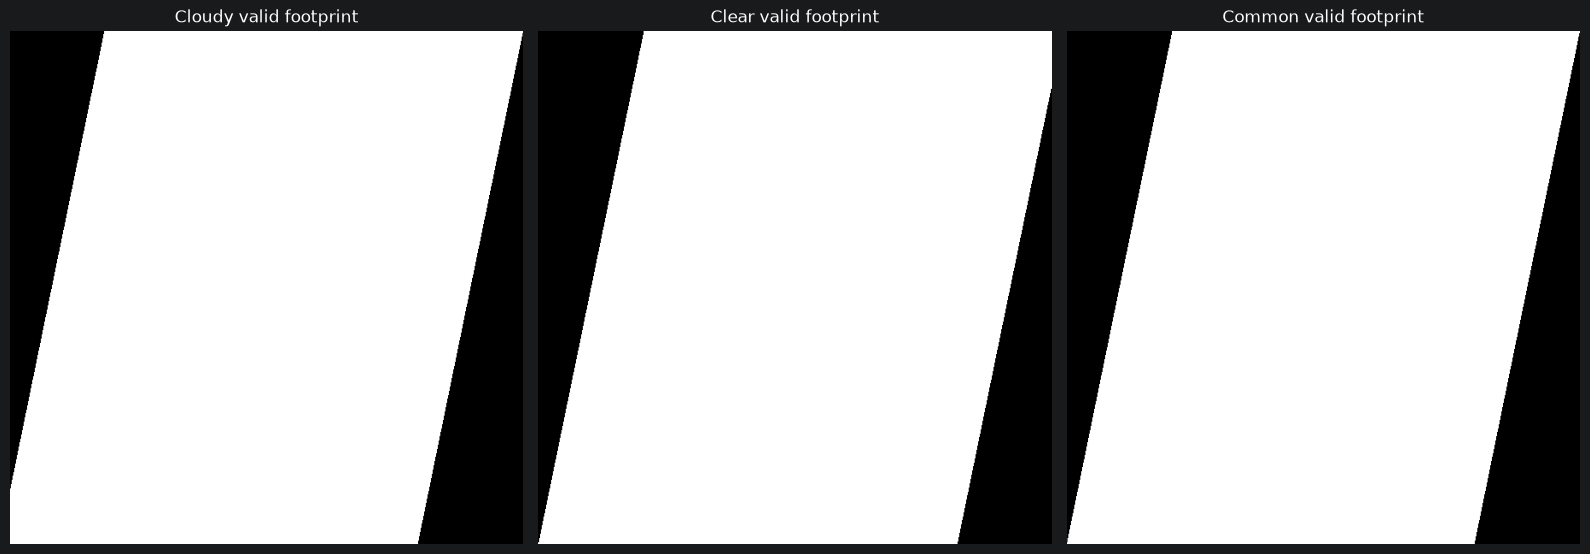

Common valid percentage: 79.42 %


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

with rasterio.open(cloudy_folder / "BAND2.tif") as cloudy_src, \
     rasterio.open(clear_folder / "BAND2.tif") as clear_src:

    cloudy_small = cloudy_src.read(
        1,
        window=cloudy_window,
        out_shape=(600, 600),
        resampling=Resampling.nearest
    )

    clear_small = clear_src.read(
        1,
        window=clear_window,
        out_shape=(600, 600),
        resampling=Resampling.nearest
    )

cloudy_valid = cloudy_small != 0
clear_valid = clear_small != 0

common_valid = cloudy_valid & clear_valid

axes[0].imshow(cloudy_valid, cmap="gray")
axes[0].set_title("Cloudy valid footprint")

axes[1].imshow(clear_valid, cmap="gray")
axes[1].set_title("Clear valid footprint")

axes[2].imshow(common_valid, cmap="gray")
axes[2].set_title("Common valid footprint")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Common valid percentage:",
      round(common_valid.mean() * 100, 2), "%")

In [24]:
from pathlib import Path

ALIGNED_ROOT = Path(r"D:\CloudRemoval_Finetune\aligned")
PAIR_OUTPUT = ALIGNED_ROOT / PAIR_ID

CLOUDY_OUTPUT = PAIR_OUTPUT / "cloudy"
CLEAR_OUTPUT = PAIR_OUTPUT / "clear"

CLOUDY_OUTPUT.mkdir(parents=True, exist_ok=True)
CLEAR_OUTPUT.mkdir(parents=True, exist_ok=True)

print("Cloudy output:", CLOUDY_OUTPUT)
print("Clear output:", CLEAR_OUTPUT)

Cloudy output: D:\CloudRemoval_Finetune\aligned\Pair1_Bengaluru\cloudy
Clear output: D:\CloudRemoval_Finetune\aligned\Pair1_Bengaluru\clear


In [25]:
from rasterio.windows import Window, transform as window_transform

cloudy_sources = [rasterio.open(cloudy_folder / b) for b in BANDS]
clear_sources = [rasterio.open(clear_folder / b) for b in BANDS]

try:
    profile = cloudy_sources[0].profile.copy()
    profile.update(
        driver="GTiff",
        width=int(cloudy_window.width),
        height=int(cloudy_window.height),
        transform=window_transform(
            cloudy_window, cloudy_sources[0].transform
        ),
        count=1,
        dtype="uint16",
        nodata=0,
        compress="lzw"
    )

    cloudy_destinations = [
        rasterio.open(CLOUDY_OUTPUT / band, "w", **profile)
        for band in BANDS
    ]

    clear_destinations = [
        rasterio.open(CLEAR_OUTPUT / band, "w", **profile)
        for band in BANDS
    ]

    try:
        CHUNK = 512

        for row in range(0, height, CHUNK):
            for col in range(0, width, CHUNK):

                h = min(CHUNK, height - row)
                w = min(CHUNK, width - col)

                cw = Window(
                    cloudy_window.col_off + col,
                    cloudy_window.row_off + row,
                    w, h
                )

                rw = Window(
                    clear_window.col_off + col,
                    clear_window.row_off + row,
                    w, h
                )

                cloudy_data = [
                    src.read(1, window=cw) for src in cloudy_sources
                ]

                clear_data = [
                    src.read(1, window=rw) for src in clear_sources
                ]

                valid = np.ones((h, w), dtype=bool)

                for arr in cloudy_data + clear_data:
                    valid &= (arr != 0)

                for i in range(3):
                    cloudy_destinations[i].write(
                        np.where(valid, cloudy_data[i], 0).astype(np.uint16),
                        1,
                        window=Window(col, row, w, h)
                    )

                    clear_destinations[i].write(
                        np.where(valid, clear_data[i], 0).astype(np.uint16),
                        1,
                        window=Window(col, row, w, h)
                    )

    finally:
        for dst in cloudy_destinations + clear_destinations:
            dst.close()

finally:
    for src in cloudy_sources + clear_sources:
        src.close()

print("Pair1 common-scene images saved successfully.")

Pair1 common-scene images saved successfully.


In [26]:
for band in BANDS:

    print(f"\n========== {band} ==========")

    for label, folder in [
        ("CLOUDY", CLOUDY_OUTPUT),
        ("CLEAR", CLEAR_OUTPUT)
    ]:

        with rasterio.open(folder / band) as src:
            data = src.read(1)

            print(f"\n{label}")
            print("Shape:", data.shape)
            print("CRS:", src.crs)
            print("Resolution:", src.res)
            print("Data type:", src.dtypes[0])
            print("Nodata:", src.nodata)
            print("Zero percentage:",
                  round(100 * np.count_nonzero(data == 0) / data.size, 2))


========== BAND2.tif ==========

CLOUDY
Shape: (16595, 17354)
CRS: EPSG:32643
Resolution: (5.0, 5.0)
Data type: uint16
Nodata: 0.0
Zero percentage: 20.58

CLEAR
Shape: (16595, 17354)
CRS: EPSG:32643
Resolution: (5.0, 5.0)
Data type: uint16
Nodata: 0.0
Zero percentage: 20.58

========== BAND3.tif ==========

CLOUDY
Shape: (16595, 17354)
CRS: EPSG:32643
Resolution: (5.0, 5.0)
Data type: uint16
Nodata: 0.0
Zero percentage: 20.58

CLEAR
Shape: (16595, 17354)
CRS: EPSG:32643
Resolution: (5.0, 5.0)
Data type: uint16
Nodata: 0.0
Zero percentage: 20.58

========== BAND4.tif ==========

CLOUDY
Shape: (16595, 17354)
CRS: EPSG:32643
Resolution: (5.0, 5.0)
Data type: uint16
Nodata: 0.0
Zero percentage: 20.58

CLEAR
Shape: (16595, 17354)
CRS: EPSG:32643
Resolution: (5.0, 5.0)
Data type: uint16
Nodata: 0.0
Zero percentage: 20.58


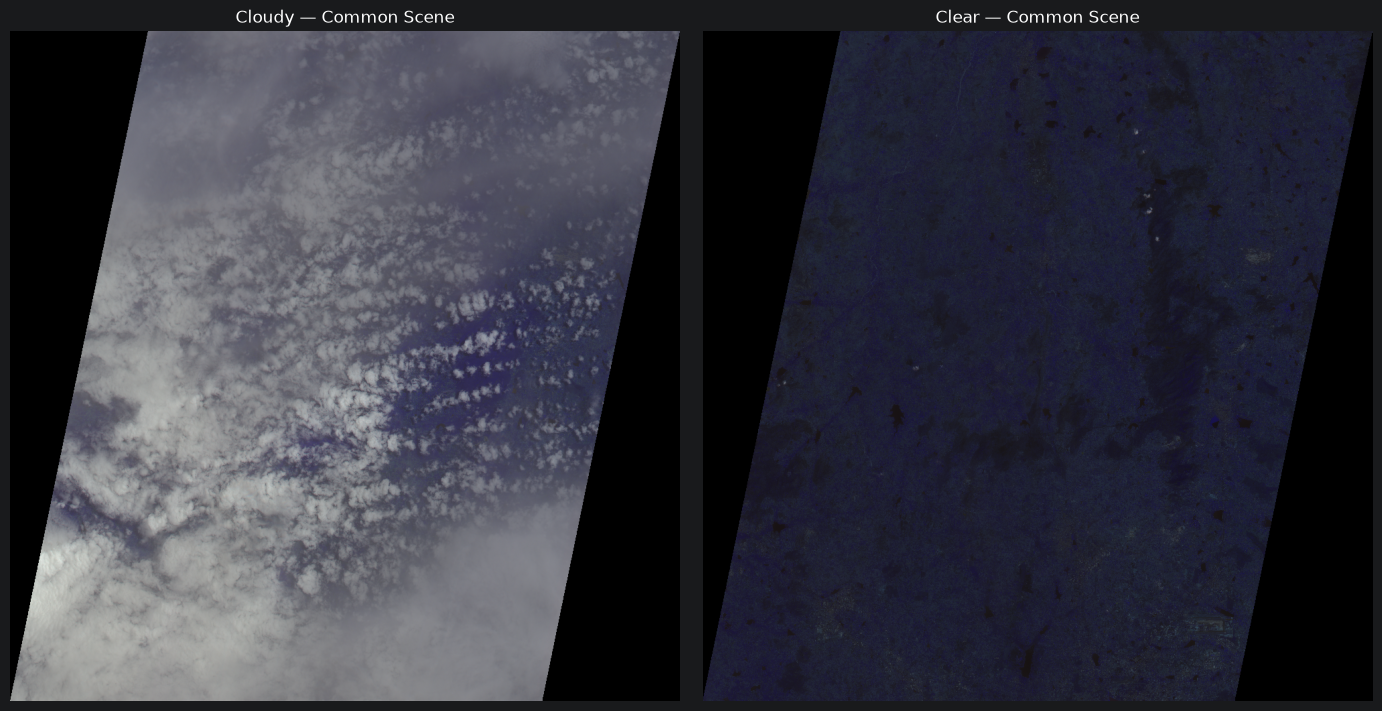

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, folder, title in [
    (axes[0], CLOUDY_OUTPUT, "Cloudy — Common Scene"),
    (axes[1], CLEAR_OUTPUT, "Clear — Common Scene")
]:
    bands = []

    for band in BANDS:
        with rasterio.open(folder / band) as src:
            data = src.read(
                1,
                out_shape=(1000, 1000),
                resampling=Resampling.nearest
            )
            bands.append(data)

    image = np.stack(bands, axis=-1)

    ax.imshow(np.clip(image / 1023, 0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
PATCH_SIZE = 256
STRIDE = 128

PATCH_ROOT = Path(r"D:\CloudRemoval_Finetune\patches\Pair1_Bengaluru")

CLOUDY_PATCH_DIR = PATCH_ROOT / "cloudy"
CLEAR_PATCH_DIR = PATCH_ROOT / "clear"

CLOUDY_PATCH_DIR.mkdir(parents=True, exist_ok=True)
CLEAR_PATCH_DIR.mkdir(parents=True, exist_ok=True)

sources_cloudy = [
    rasterio.open(CLOUDY_OUTPUT / band) for band in BANDS
]

sources_clear = [
    rasterio.open(CLEAR_OUTPUT / band) for band in BANDS
]

patch_count = 0
skipped_count = 0

try:
    height = sources_cloudy[0].height
    width = sources_cloudy[0].width

    for row in range(0, height - PATCH_SIZE + 1, STRIDE):
        for col in range(0, width - PATCH_SIZE + 1, STRIDE):

            window = Window(col, row, PATCH_SIZE, PATCH_SIZE)

            cloudy_data = [
                src.read(1, window=window) for src in sources_cloudy
            ]

            clear_data = [
                src.read(1, window=window) for src in sources_clear
            ]

            valid = np.ones((PATCH_SIZE, PATCH_SIZE), dtype=bool)

            for band_data in cloudy_data + clear_data:
                valid &= band_data != 0

            if not valid.all():
                skipped_count += 1
                continue

            patch_name = f"patch_{patch_count:06d}.tif"

            for data, sources, output_dir in [
                (cloudy_data, sources_cloudy, CLOUDY_PATCH_DIR),
                (clear_data, sources_clear, CLEAR_PATCH_DIR)
            ]:

                profile = sources[0].profile.copy()
                profile.update(
                    driver="GTiff",
                    height=PATCH_SIZE,
                    width=PATCH_SIZE,
                    count=3,
                    dtype="uint16",
                    transform=rasterio.windows.transform(
                        window, sources[0].transform
                    ),
                    compress="lzw"
                )

                with rasterio.open(output_dir / patch_name, "w", **profile) as dst:
                    for band_index, band_data in enumerate(data, start=1):
                        dst.write(band_data, band_index)

            patch_count += 1

finally:
    for src in sources_cloudy + sources_clear:
        src.close()

print("Patch generation completed.")
print("Valid paired patches:", patch_count)
print("Skipped patches:", skipped_count)
print("Total TIFF files:", patch_count * 2)

Patch generation completed.
Valid paired patches: 13474
Skipped patches: 3678
Total TIFF files: 26948


In [29]:
remaining_pairs = [
    "Pair4_Pune",
    "Pair5_Pune",
    "Pair9_Raipur",
    "Pair11_Raipur",
    "Pair13_Vijayawada",
    "Pair14_Vijayawada",
    "Pair15_Guntur",
    "Pair16_Guntur",
    "Pair17_Dharwad",
    "Pair18_Dharwad",
    "Pair19_Dharwad",
    "Pair20_Dharwad"
]

print("Remaining pairs:", len(remaining_pairs))
for pair in remaining_pairs:
    print(pair)

Remaining pairs: 12
Pair4_Pune
Pair5_Pune
Pair9_Raipur
Pair11_Raipur
Pair13_Vijayawada
Pair14_Vijayawada
Pair15_Guntur
Pair16_Guntur
Pair17_Dharwad
Pair18_Dharwad
Pair19_Dharwad
Pair20_Dharwad


In [32]:
import rasterio
import numpy as np
from rasterio.windows import Window
from pathlib import Path

BANDS = ["BAND2.tif", "BAND3.tif", "BAND4.tif"]
CHUNK_SIZE = 1024

for pair in remaining_pairs:
    print(f"\nProcessing {pair}...")

    cloudy_dir = CLOUDY_DIR / pair
    clear_dir = CLEAR_DIR / pair

    cloudy_files = [cloudy_dir / b for b in BANDS]
    clear_files = [clear_dir / b for b in BANDS]

    with rasterio.open(cloudy_files[0]) as c, rasterio.open(clear_files[0]) as r:
        if c.crs != r.crs or c.res != r.res:
            print(f"Skipping {pair}: CRS or resolution mismatch.")
            continue

        col_offset_float = (r.transform.c - c.transform.c) / c.res[0]
        row_offset_float = (c.transform.f - r.transform.f) / abs(c.res[1])

        col_offset = round(col_offset_float)
        row_offset = round(row_offset_float)

        if not np.isclose(col_offset_float, col_offset, atol=1e-6) or not np.isclose(row_offset_float, row_offset, atol=1e-6):
            print(f"Skipping {pair}: pixel grids are not aligned.")
            continue

        col_start_c = max(0, col_offset)
        row_start_c = max(0, row_offset)
        col_start_r = max(0, -col_offset)
        row_start_r = max(0, -row_offset)

        width = min(c.width - col_start_c, r.width - col_start_r)
        height = min(c.height - row_start_c, r.height - row_start_r)

        if width <= 0 or height <= 0:
            print(f"Skipping {pair}: no overlap.")
            continue

        cloudy_window = Window(col_start_c, row_start_c, width, height)
        clear_window = Window(col_start_r, row_start_r, width, height)

        cloudy_src = [rasterio.open(p) for p in cloudy_files]
        clear_src = [rasterio.open(p) for p in clear_files]

        try:
            cloudy_profile = cloudy_src[0].profile.copy()
            cloudy_profile.update(
                height=height, width=width, nodata=0,
                dtype="uint16", compress="lzw"
            )

            clear_profile = clear_src[0].profile.copy()
            clear_profile.update(
                height=height, width=width, nodata=0,
                dtype="uint16", compress="lzw"
            )

            out_cloudy = ALIGNED_ROOT / pair / "cloudy"
            out_clear = ALIGNED_ROOT / pair / "clear"
            out_cloudy.mkdir(parents=True, exist_ok=True)
            out_clear.mkdir(parents=True, exist_ok=True)

            cloudy_dst = [
                rasterio.open(out_cloudy / b, "w", **cloudy_profile)
                for b in BANDS
            ]
            clear_dst = [
                rasterio.open(out_clear / b, "w", **clear_profile)
                for b in BANDS
            ]

            try:
                for row in range(0, height, CHUNK_SIZE):
                    h = min(CHUNK_SIZE, height - row)

                    c_arrays = [
                        src.read(1, window=Window(col_start_c, row_start_c + row, width, h))
                        for src in cloudy_src
                    ]
                    r_arrays = [
                        src.read(1, window=Window(col_start_r, row_start_r + row, width, h))
                        for src in clear_src
                    ]

                    valid = np.ones((h, width), dtype=bool)
                    for arr in c_arrays + r_arrays:
                        valid &= arr != 0

                    for dst, arr in zip(cloudy_dst, c_arrays):
                        dst.write(np.where(valid, arr, 0).astype(np.uint16), 1,
                                  window=Window(0, row, width, h))

                    for dst, arr in zip(clear_dst, r_arrays):
                        dst.write(np.where(valid, arr, 0).astype(np.uint16), 1,
                                  window=Window(0, row, width, h))

            finally:
                for dst in cloudy_dst + clear_dst:
                    dst.close()

            print(f"Completed {pair}: {height} x {width}")

        finally:
            for src in cloudy_src + clear_src:
                src.close()

print("\nBatch alignment finished.")


Processing Pair4_Pune...
Completed Pair4_Pune: 16331 x 17931

Processing Pair5_Pune...
Completed Pair5_Pune: 16219 x 17329

Processing Pair9_Raipur...
Completed Pair9_Raipur: 16508 x 17709

Processing Pair11_Raipur...
Completed Pair11_Raipur: 16633 x 17817

Processing Pair13_Vijayawada...
Completed Pair13_Vijayawada: 16326 x 17788

Processing Pair14_Vijayawada...
Completed Pair14_Vijayawada: 16244 x 17894

Processing Pair15_Guntur...
Completed Pair15_Guntur: 16404 x 17691

Processing Pair16_Guntur...
Completed Pair16_Guntur: 16286 x 17896

Processing Pair17_Dharwad...
Completed Pair17_Dharwad: 15232 x 17428

Processing Pair18_Dharwad...
Completed Pair18_Dharwad: 16346 x 17611

Processing Pair19_Dharwad...
Completed Pair19_Dharwad: 16385 x 17799

Processing Pair20_Dharwad...
Completed Pair20_Dharwad: 16377 x 17397

Batch alignment finished.


In [33]:
import rasterio
import numpy as np
from rasterio.windows import Window
from pathlib import Path

PATCH_SIZE = 256
STRIDE = 128
BANDS = ["BAND2.tif", "BAND3.tif", "BAND4.tif"]

for pair in remaining_pairs:
    print(f"\nProcessing patches: {pair}")

    cloudy_dir = ALIGNED_ROOT / pair / "cloudy"
    clear_dir = ALIGNED_ROOT / pair / "clear"

    cloudy_files = [cloudy_dir / b for b in BANDS]
    clear_files = [clear_dir / b for b in BANDS]

    cloudy_src = [rasterio.open(p) for p in cloudy_files]
    clear_src = [rasterio.open(p) for p in clear_files]

    try:
        height = cloudy_src[0].height
        width = cloudy_src[0].width

        cloudy_out = PATCHES_ROOT / pair / "cloudy"
        clear_out = PATCHES_ROOT / pair / "clear"

        cloudy_out.mkdir(parents=True, exist_ok=True)
        clear_out.mkdir(parents=True, exist_ok=True)

        saved = 0
        skipped = 0

        for row in range(0, height - PATCH_SIZE + 1, STRIDE):
            for col in range(0, width - PATCH_SIZE + 1, STRIDE):

                window = Window(col, row, PATCH_SIZE, PATCH_SIZE)

                cloudy_arrays = [
                    src.read(1, window=window) for src in cloudy_src
                ]
                clear_arrays = [
                    src.read(1, window=window) for src in clear_src
                ]

                valid = np.ones((PATCH_SIZE, PATCH_SIZE), dtype=bool)

                for arr in cloudy_arrays + clear_arrays:
                    valid &= arr != 0

                if not valid.all():
                    skipped += 1
                    continue

                patch_name = f"patch_{row}_{col}.tif"

                for arrays, sources, output_dir in [
                    (cloudy_arrays, cloudy_src, cloudy_out),
                    (clear_arrays, clear_src, clear_out)
                ]:
                    profile = sources[0].profile.copy()
                    profile.update(
                        height=PATCH_SIZE,
                        width=PATCH_SIZE,
                        count=3,
                        dtype="uint16",
                        nodata=0,
                        compress="lzw",
                        transform=rasterio.windows.transform(
                            window, sources[0].transform
                        )
                    )

                    with rasterio.open(output_dir / patch_name, "w", **profile) as dst:
                        for band_idx, arr in enumerate(arrays, start=1):
                            dst.write(arr.astype(np.uint16), band_idx)

                saved += 1

        print(f"Saved paired patches: {saved}")
        print(f"Skipped patches: {skipped}")

    finally:
        for src in cloudy_src + clear_src:
            src.close()

print("\nPatch generation completed.")


Processing patches: Pair4_Pune
Saved paired patches: 13617
Skipped patches: 3897

Processing patches: Pair5_Pune
Saved paired patches: 12845
Skipped patches: 3905

Processing patches: Pair9_Raipur
Saved paired patches: 13422
Skipped patches: 3977

Processing patches: Pair11_Raipur
Saved paired patches: 13732
Skipped patches: 3932

Processing patches: Pair13_Vijayawada
Saved paired patches: 13477
Skipped patches: 3785

Processing patches: Pair14_Vijayawada
Saved paired patches: 13524
Skipped patches: 3726

Processing patches: Pair15_Guntur
Saved paired patches: 13393
Skipped patches: 4006

Processing patches: Pair16_Guntur
Saved paired patches: 13605
Skipped patches: 3783

Processing patches: Pair17_Dharwad
Saved paired patches: 12582
Skipped patches: 3348

Processing patches: Pair18_Dharwad
Saved paired patches: 13342
Skipped patches: 3794

Processing patches: Pair19_Dharwad
Saved paired patches: 13625
Skipped patches: 3901

Processing patches: Pair20_Dharwad
Saved paired patches: 131

In [34]:
from pathlib import Path

for pair in remaining_pairs:
    cloudy_dir = PATCHES_ROOT / pair / "cloudy"
    clear_dir = PATCHES_ROOT / pair / "clear"

    cloudy_files = {p.name for p in cloudy_dir.glob("*.tif")}
    clear_files = {p.name for p in clear_dir.glob("*.tif")}

    print(f"\n{pair}")
    print("Cloudy patches:", len(cloudy_files))
    print("Clear patches:", len(clear_files))
    print("Matching pairs:", len(cloudy_files & clear_files))
    print("Unmatched cloudy:", len(cloudy_files - clear_files))
    print("Unmatched clear:", len(clear_files - cloudy_files))

print("\nTotal paired patches:", sum(
    len({p.name for p in (PATCHES_ROOT / pair / "cloudy").glob("*.tif")} &
        {p.name for p in (PATCHES_ROOT / pair / "clear").glob("*.tif")})
    for pair in remaining_pairs
))


Pair4_Pune
Cloudy patches: 13617
Clear patches: 13617
Matching pairs: 13617
Unmatched cloudy: 0
Unmatched clear: 0

Pair5_Pune
Cloudy patches: 12845
Clear patches: 12845
Matching pairs: 12845
Unmatched cloudy: 0
Unmatched clear: 0

Pair9_Raipur
Cloudy patches: 13422
Clear patches: 13422
Matching pairs: 13422
Unmatched cloudy: 0
Unmatched clear: 0

Pair11_Raipur
Cloudy patches: 13732
Clear patches: 13732
Matching pairs: 13732
Unmatched cloudy: 0
Unmatched clear: 0

Pair13_Vijayawada
Cloudy patches: 13477
Clear patches: 13477
Matching pairs: 13477
Unmatched cloudy: 0
Unmatched clear: 0

Pair14_Vijayawada
Cloudy patches: 13524
Clear patches: 13524
Matching pairs: 13524
Unmatched cloudy: 0
Unmatched clear: 0

Pair15_Guntur
Cloudy patches: 13393
Clear patches: 13393
Matching pairs: 13393
Unmatched cloudy: 0
Unmatched clear: 0

Pair16_Guntur
Cloudy patches: 13605
Clear patches: 13605
Matching pairs: 13605
Unmatched cloudy: 0
Unmatched clear: 0

Pair17_Dharwad
Cloudy patches: 12582
Clear pat

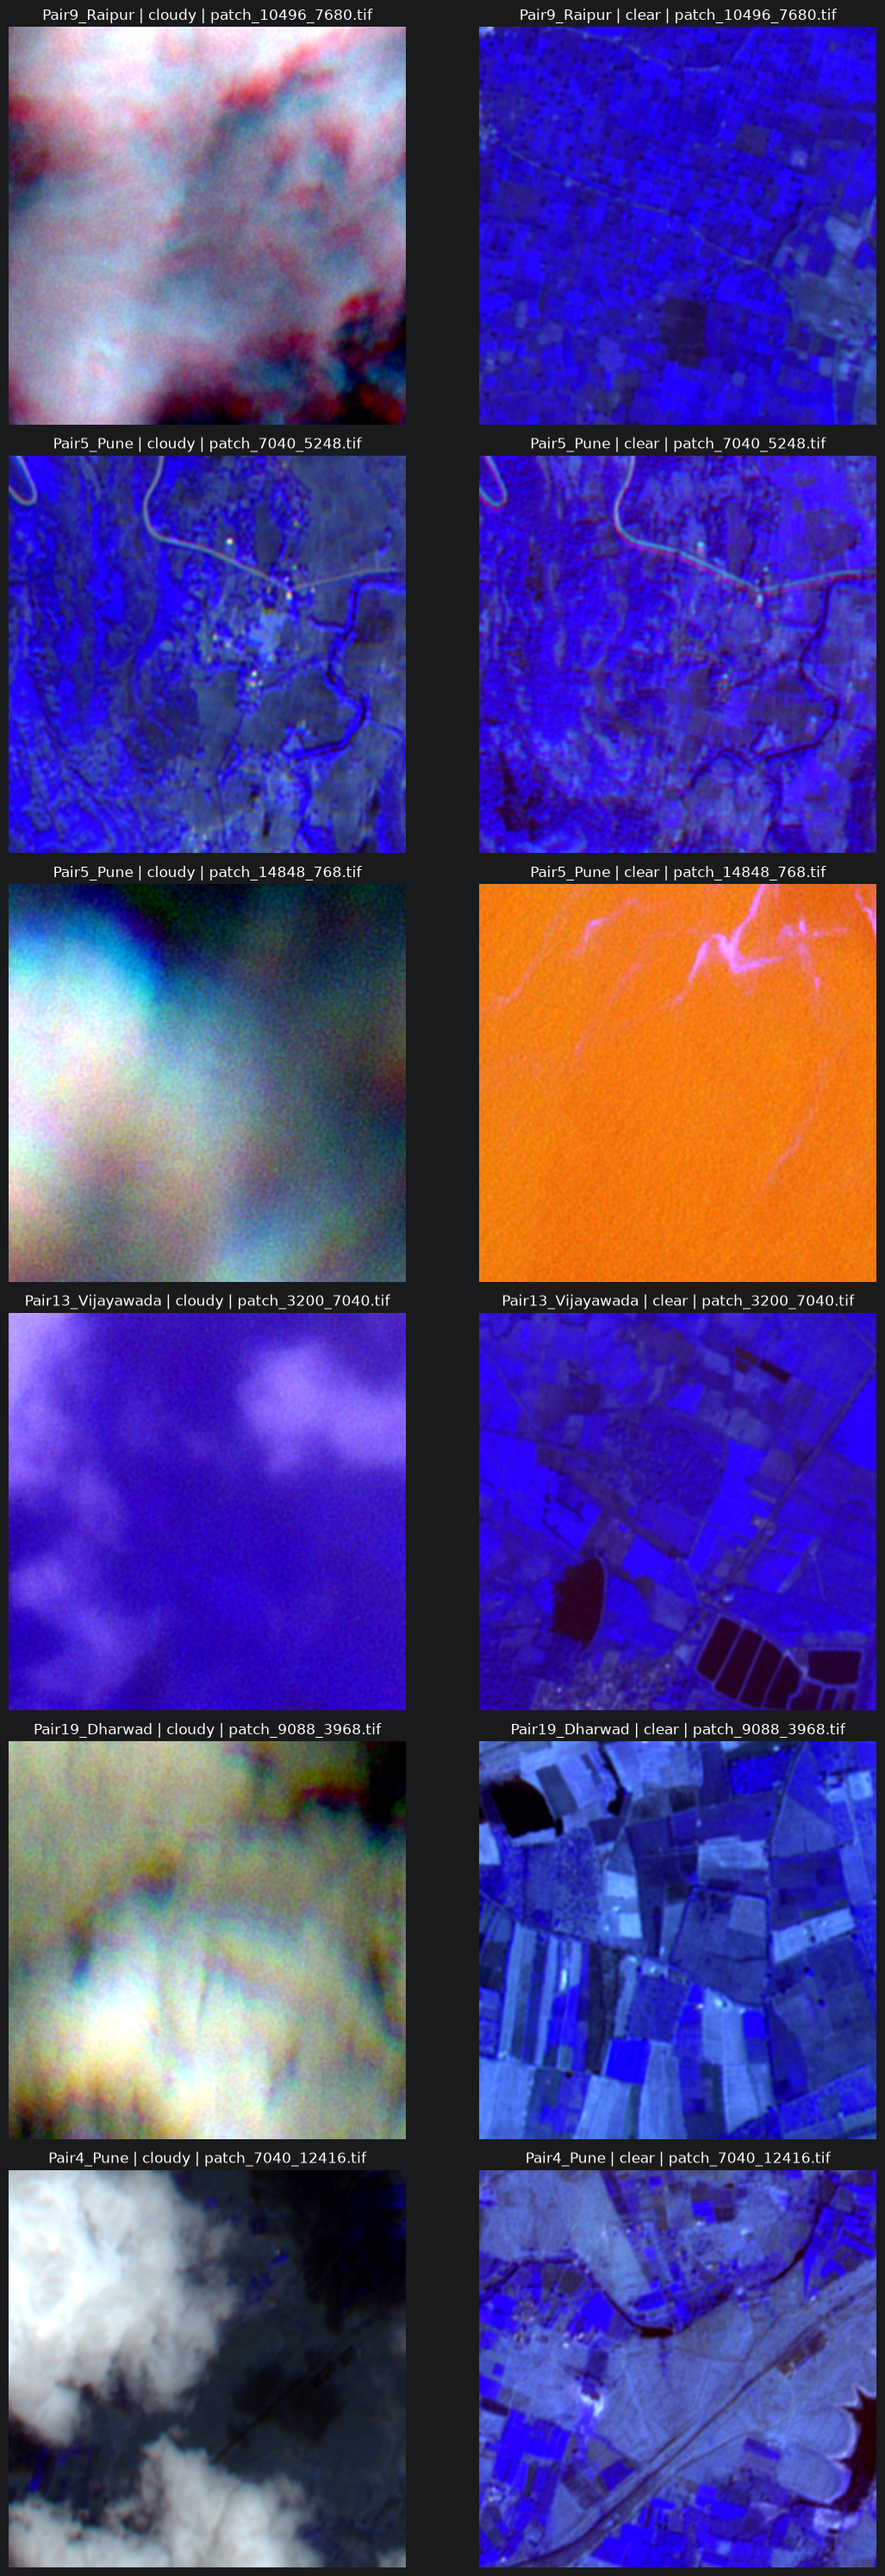

In [36]:
import random
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path

NUM_SAMPLES = 6

# Collect all available paired patches
all_pairs = []

for pair in remaining_pairs:
    cloudy_dir = PATCHES_ROOT / pair / "cloudy"
    clear_dir = PATCHES_ROOT / pair / "clear"

    cloudy_files = {p.name for p in cloudy_dir.glob("*.tif")}
    clear_files = {p.name for p in clear_dir.glob("*.tif")}

    for filename in cloudy_files & clear_files:
        all_pairs.append((pair, filename))

samples = random.sample(all_pairs, min(NUM_SAMPLES, len(all_pairs)))

fig, axes = plt.subplots(len(samples), 2, figsize=(12, 5 * len(samples)))

if len(samples) == 1:
    axes = np.expand_dims(axes, axis=0)

for i, (pair, filename) in enumerate(samples):
    for j, condition in enumerate(["cloudy", "clear"]):
        path = PATCHES_ROOT / pair / condition / filename

        with rasterio.open(path) as src:
            image = np.stack([
                src.read(1),
                src.read(2),
                src.read(3)
            ], axis=-1)

        # Percentile stretch for visualization only
        low, high = np.percentile(image, (2, 98))
        image = np.clip((image.astype(np.float32) - low) / (high - low + 1e-8), 0, 1)

        axes[i, j].imshow(image)
        axes[i, j].set_title(f"{pair} | {condition} | {filename}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [37]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

PATCHES_ROOT = Path(r"D:\CloudRemoval_Finetune\patches")

CSV_PATH = PATCHES_ROOT / "patch_manifest.csv"

RANDOM_STATE = 42

In [38]:
all_pairs = []

for scene_dir in sorted(PATCHES_ROOT.iterdir()):

    if not scene_dir.is_dir():
        continue

    cloudy_dir = scene_dir / "cloudy"
    clear_dir = scene_dir / "clear"

    if not cloudy_dir.exists() or not clear_dir.exists():
        continue

    cloudy_files = {p.name: p for p in cloudy_dir.glob("*.tif")}
    clear_files = {p.name: p for p in clear_dir.glob("*.tif")}

    common_files = sorted(set(cloudy_files) & set(clear_files))

    print(
        f"{scene_dir.name}: "
        f"{len(common_files)} paired patches"
    )

    for filename in common_files:
        all_pairs.append({
            "pair_id": scene_dir.name,
            "patch_name": filename,
            "cloudy_path": str(cloudy_files[filename].resolve()),
            "clear_path": str(clear_files[filename].resolve())
        })

manifest = pd.DataFrame(all_pairs)

print("\nTotal paired patches:", len(manifest))
print("Total scenes:", manifest["pair_id"].nunique())

Pair11_Raipur: 13732 paired patches
Pair13_Vijayawada: 13477 paired patches
Pair14_Vijayawada: 13524 paired patches
Pair15_Guntur: 13393 paired patches
Pair16_Guntur: 13605 paired patches
Pair17_Dharwad: 12582 paired patches
Pair18_Dharwad: 13342 paired patches
Pair19_Dharwad: 13625 paired patches
Pair1_Bengaluru: 13474 paired patches
Pair20_Dharwad: 13123 paired patches
Pair4_Pune: 13617 paired patches
Pair5_Pune: 12845 paired patches
Pair9_Raipur: 13422 paired patches

Total paired patches: 173761
Total scenes: 13


In [39]:
assert manifest["pair_id"].nunique() >= 3

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=RANDOM_STATE
)

train_val_idx, test_idx = next(
    gss.split(manifest, groups=manifest["pair_id"])
)

train_val = manifest.iloc[train_val_idx].copy()
test = manifest.iloc[test_idx].copy()

gss_val = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15 / 0.85,
    random_state=RANDOM_STATE
)

train_idx, val_idx = next(
    gss_val.split(train_val, groups=train_val["pair_id"])
)

train = train_val.iloc[train_idx].copy()
valid = train_val.iloc[val_idx].copy()

train["split"] = "train"
valid["split"] = "valid"
test["split"] = "test"

manifest = pd.concat(
    [train, valid, test],
    ignore_index=True
)

print("Splitting completed.")

Splitting completed.


In [40]:
for split_name in ["train", "valid", "test"]:

    subset = manifest[manifest["split"] == split_name]

    print(f"\n{split_name.upper()}")
    print("Patches:", len(subset))
    print("Scenes:", subset["pair_id"].nunique())

train_scenes = set(train["pair_id"])
valid_scenes = set(valid["pair_id"])
test_scenes = set(test["pair_id"])

assert train_scenes.isdisjoint(valid_scenes)
assert train_scenes.isdisjoint(test_scenes)
assert valid_scenes.isdisjoint(test_scenes)

assert len(manifest) == len(train) + len(valid) + len(test)

print("\nNo scene overlap. Split verification passed.")


TRAIN
Patches: 121479
Scenes: 9

VALID
Patches: 26314
Scenes: 2

TEST
Patches: 25968
Scenes: 2

No scene overlap. Split verification passed.


In [41]:
manifest = manifest.sort_values(
    ["split", "pair_id", "patch_name"]
).reset_index(drop=True)

manifest.to_csv(CSV_PATH, index=False)

print("CSV saved successfully!")
print("Location:", CSV_PATH)
print("Total records:", len(manifest))

CSV saved successfully!
Location: D:\CloudRemoval_Finetune\patches\patch_manifest.csv
Total records: 173761


In [42]:
summary = manifest.groupby("split").agg(
    total_patches=("patch_name", "count"),
    total_scenes=("pair_id", "nunique")
)

summary["percentage"] = (
    summary["total_patches"] / len(manifest) * 100
).round(2)

display(summary)

,total_patches,total_scenes,percentage
split,,,
test,25968,2,14.94
train,121479,9,69.91
valid,26314,2,15.14
